<a href="https://colab.research.google.com/github/vesakhaa/Statistika_Semester_3/blob/main/StatistikaJobSheet3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Mean  : 3.7263636363636365
Median: 4.0
Modus : 4
Mean total_penjualan  : 14819334.545454545
Median total_penjualan: 9676000.0
                                 mean           std           var
kategori_produk                                                  
Aksesoris                6.215336e+05  3.441138e+05  1.184143e+11
Elektronik Rumah Tangga  3.968427e+06  2.094034e+06  4.384978e+12
Laptop                   1.226934e+07  3.227053e+06  1.041387e+13
Smartphone               6.825129e+06  2.959924e+06  8.761150e+12
Q1 : 9512500.0
Q3 : 15237500.0
IQR: 5725000.0
Batas outlier: 925000.0 - 23825000.0


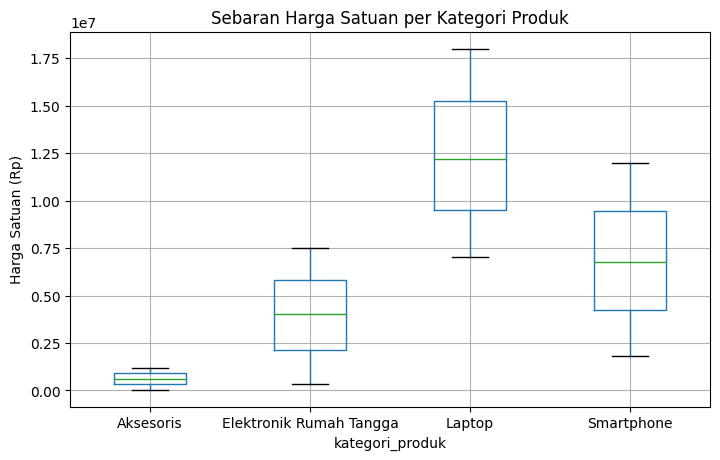

In [ ]:
# @title Teks judul default
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('transaksi_elektronikprima.csv')
df.head()

mean_rating = df['rating_kepuasan'].mean()
median_rating = df['rating_kepuasan'].median()
modus_rating = df['rating_kepuasan'].mode()[0]

print('Mean  :', mean_rating)
print('Median:', median_rating)
print('Modus :', modus_rating)

mean_tp = df['total_penjualan'].mean()
median_tp = df['total_penjualan'].median()

print('Mean total_penjualan  :', mean_tp)
print('Median total_penjualan:', median_tp)

variabilitas = df.groupby('kategori_produk')['harga_satuan']\
                 .agg(['mean', 'std', 'var'])
print(variabilitas)

laptop = df[df['kategori_produk'] == 'Laptop']['harga_satuan']
q1 = laptop.quantile(0.25)
q3 = laptop.quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

print('Q1 :', q1)
print('Q3 :', q3)
print('IQR:', iqr)
print('Batas outlier:', batas_bawah, '-', batas_atas)

df.boxplot(column='harga_satuan', by='kategori_produk', figsize=(8,5))
plt.title('Sebaran Harga Satuan per Kategori Produk')
plt.suptitle('')
plt.ylabel('Harga Satuan (Rp)')
plt.show()


Mean Surabaya  : 13722991.482112436
Median Surabaya: 9250000.0
Standar Deviasi Smartphone: 2959923.938981172
Varians Smartphone        : 8761149724553.817


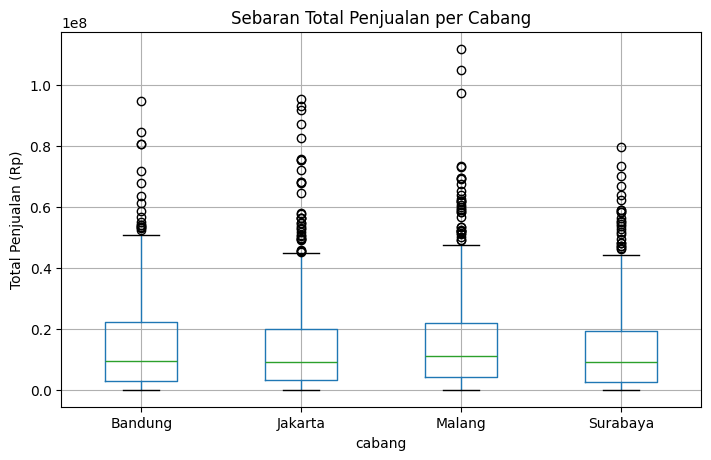

In [ ]:
# Filter cabang Surabaya
df_sby = df[df['cabang'] == 'Surabaya']

# Hitung mean dan median
mean_sby = df_sby['total_penjualan'].mean()
median_sby = df_sby['total_penjualan'].median()

print('Mean Surabaya  :', mean_sby)
print('Median Surabaya:', median_sby)

# Filter kategori Smartphone
df_sp = df[df['kategori_produk'] == 'Smartphone']

# Hitung standar deviasi dan varians
std_sp = df_sp['harga_satuan'].std()
var_sp = df_sp['harga_satuan'].var()

print('Standar Deviasi Smartphone:', std_sp)
print('Varians Smartphone        :', var_sp)

df.boxplot(column='total_penjualan', by='cabang', figsize=(8,5))
plt.title('Sebaran Total Penjualan per Cabang')
plt.suptitle('')
plt.ylabel('Total Penjualan (Rp)')
plt.show()